# Week 4: Statistical Analysis and Predictive Modeling in Agribusiness

**Dataset:** Agriculture and Farming Dataset (Kaggle), 50 farms, declared as a source in Week 1.
**Target:** Yield (tons). **Predictors:** farm area, fertilizer, pesticide, water usage, plus irrigation type, soil type, season and crop type.
**Question:** do these variables explain or predict yield?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("D:\\PROJECT\\Yuva Intern\\Datasets\\agriculture_dataset.csv")
print(df.shape)
print(df.describe())
print(df[['Farm_Area(acres)','Fertilizer_Used(tons)','Pesticide_Used(kg)',
          'Water_Usage(cubic meters)','Yield(tons)']].corr()['Yield(tons)'])

(50, 10)
       Farm_Area(acres)  Fertilizer_Used(tons)  Pesticide_Used(kg)  \
count         50.000000              50.000000           50.000000   
mean         254.963800               4.905400            2.398000   
std          139.417782               2.732689            1.438613   
min           12.500000               0.500000            0.140000   
25%          135.710000               2.437500            0.972500   
50%          281.980000               5.045000            2.330000   
75%          368.107500               6.885000            3.417500   
max          483.880000               9.960000            4.990000   

       Yield(tons)  Water_Usage(cubic meters)  
count    50.000000                  50.000000  
mean     27.059200               56724.295600  
std      13.345789               27264.992053  
min       3.860000                5869.750000  
25%      16.190000               37818.152500  
50%      28.970000               54097.075000  
75%      37.860000      

In [2]:
df.head()

,Farm_ID,Crop_Type,Farm_Area(acres),Irrigation_Type,Fertilizer_Used(tons),Pesticide_Used(kg),Yield(tons),Soil_Type,Season,Water_Usage(cubic meters)
0,F001,Cotton,329.40,Sprinkler,8.14,2.21,14.44,Loamy,Kharif,76648.20
1,F002,Carrot,18.67,Manual,4.77,4.36,42.91,Peaty,Kharif,68725.54
2,F003,Sugarcane,306.03,Flood,2.91,0.56,33.44,Silty,Kharif,75538.56
3,F004,Tomato,380.21,Rain-fed,3.32,4.35,34.08,Silty,Zaid,45401.23
4,F005,Tomato,135.56,Sprinkler,8.33,4.48,43.28,Clay,Zaid,93718.69


In [3]:
from scipy import stats

predictors = ['Farm_Area(acres)', 'Fertilizer_Used(tons)',
              'Pesticide_Used(kg)', 'Water_Usage(cubic meters)']

for col in predictors:
    r, p = stats.pearsonr(df[col], df['Yield(tons)'])
    print(f"{col}: r = {r:.3f}, p = {p:.3f}")

Farm_Area(acres): r = 0.153, p = 0.288
Fertilizer_Used(tons): r = 0.045, p = 0.756
Pesticide_Used(kg): r = -0.090, p = 0.532
Water_Usage(cubic meters): r = 0.108, p = 0.454


In [4]:
from scipy import stats

groups = [g['Yield(tons)'].values for _, g in df.groupby('Irrigation_Type')]
f, p = stats.f_oneway(*groups)
print(f"Irrigation type: F = {f:.3f}, p = {p:.3f}")

print(df.groupby('Irrigation_Type')['Yield(tons)'].agg(['count', 'mean']))

Irrigation type: F = 1.413, p = 0.245
                 count       mean
Irrigation_Type                  
Drip                15  26.769333
Flood               13  20.893077
Manual               6  34.160000
Rain-fed             7  31.980000
Sprinkler            9  27.887778


In [5]:
stat, p = stats.levene(*groups)
print(f"Levene test for equal variances: p = {p:.3f}")

Levene test for equal variances: p = 0.755


## Do Average Yields Differ Between Groups? (One-Way ANOVA)
H0: all group averages are equal. H1: at least one differs.
Assumptions: independent farms, roughly normal yield per group, similar spread (checked with Levene's test).

In [6]:
col = 'Soil_Type'    
groups = [g['Yield(tons)'].values for _, g in df.groupby(col)]
f, p = stats.f_oneway(*groups)
print(f"{col}: F = {f:.3f}, p = {p:.3f}")
print(df.groupby(col)['Yield(tons)'].agg(['count', 'mean']))

Soil_Type: F = 0.341, p = 0.849
           count       mean
Soil_Type                  
Clay          14  25.042143
Loamy         11  27.483636
Peaty          4  23.470000
Sandy         11  27.026364
Silty         10  30.888000


In [7]:
col = 'Season'    
groups = [g['Yield(tons)'].values for _, g in df.groupby(col)]
f, p = stats.f_oneway(*groups)
print(f"{col}: F = {f:.3f}, p = {p:.3f}")
print(df.groupby(col)['Yield(tons)'].agg(['count', 'mean']))

Season: F = 0.230, p = 0.796
        count       mean
Season                  
Kharif     16  27.341875
Rabi       11  24.671818
Zaid       23  28.004348


In [8]:
col = 'Crop_Type'    
groups = [g['Yield(tons)'].values for _, g in df.groupby(col)]
f, p = stats.f_oneway(*groups)
print(f"{col}: F = {f:.3f}, p = {p:.3f}")
print(df.groupby(col)['Yield(tons)'].agg(['count', 'mean']))

Crop_Type: F = 0.758, p = 0.655
           count       mean
Crop_Type                  
Barley         7  26.401429
Carrot         4  36.630000
Cotton         7  20.974286
Maize          3  20.163333
Potato         4  25.157500
Rice           5  23.586000
Soybean        5  32.310000
Sugarcane      5  26.952000
Tomato         6  33.630000
Wheat          4  24.417500


In [9]:
col = 'Irrigation_Type'   
groups = [g['Yield(tons)'].values for _, g in df.groupby(col)]
f, p = stats.f_oneway(*groups)
print(f"{col}: F = {f:.3f}, p = {p:.3f}")
print(df.groupby(col)['Yield(tons)'].agg(['count', 'mean']))

Irrigation_Type: F = 1.413, p = 0.245
                 count       mean
Irrigation_Type                  
Drip                15  26.769333
Flood               13  20.893077
Manual               6  34.160000
Rain-fed             7  31.980000
Sprinkler            9  27.887778


In [10]:
print("Missing values:", df.isnull().sum().sum(), "| Duplicate rows:", df.duplicated().sum(), "| Unique Farm_IDs:", df['Farm_ID'].nunique())

for col in ['Irrigation_Type', 'Soil_Type', 'Season', 'Crop_Type']:
    groups = [g['Yield(tons)'].values for _, g in df.groupby(col)]
    print(col, "Levene p =", round(stats.levene(*groups)[1], 3))

n = 50
t = stats.t.ppf(0.975, n - 2)
print("Smallest significant |r|:", round(t / np.sqrt(n - 2 + t**2), 3))
z = stats.norm.ppf(0.975) + stats.norm.ppf(0.80)
print("Smallest |r| detectable with 80% power:", round(np.tanh(z / np.sqrt(n - 3)), 3))
for r in [0.30, 0.15]:
    print("Farms needed for r =", r, ":", round((z / np.arctanh(r))**2 + 3))

Missing values: 0 | Duplicate rows: 0 | Unique Farm_IDs: 50
Irrigation_Type Levene p = 0.755
Soil_Type Levene p = 0.948
Season Levene p = 0.793
Crop_Type Levene p = 0.957
Smallest significant |r|: 0.279
Smallest |r| detectable with 80% power: 0.387
Farms needed for r = 0.3 : 85
Farms needed for r = 0.15 : 347


**Finding:** no grouping is significant: irrigation (p = 0.245), soil (p = 0.849), season (p = 0.796), crop type (p = 0.655). Levene's test (p = 0.755) shows the equal-spread assumption is acceptable.
**Caution:** some groups are tiny (Peaty soil has 4 farms, Manual irrigation 6, Maize 3), so their averages are unreliable.

## Multiple Linear Regression
Model: Yield = base + (a x area) + (b x fertilizer) + (c x pesticide) + (d x water).

In [11]:
import statsmodels.api as sm

df = pd.read_csv("D:\\PROJECT\\Yuva Intern\\Datasets\\agriculture_dataset.csv")

X = df[['Farm_Area(acres)', 'Fertilizer_Used(tons)',
        'Pesticide_Used(kg)', 'Water_Usage(cubic meters)']]
y = df['Yield(tons)']

X = sm.add_constant(X)
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            Yield(tons)   R-squared:                       0.048
Model:                            OLS   Adj. R-squared:                 -0.036
Method:                 Least Squares   F-statistic:                    0.5709
Date:                Sun, 11 Oct 2026   Prob (F-statistic):              0.685
Time:                        08:42:07   Log-Likelihood:                -198.76
No. Observations:                  50   AIC:                             407.5
Df Residuals:                      45   BIC:                             417.1
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                 

**Finding:** R-squared = 0.048 and adjusted R-squared = -0.036, so the inputs explain almost none of the variation in yield. The overall F-test (p = 0.685) shows the model is no better than guessing the average, and no individual input is significant. The fertilizer coefficient (0.29 tons per extra ton) has a confidence interval of -1.16 to 1.74, which includes zero.

## Does the Model Work on Unseen Farms?
80% of farms are used to build the model and 20% are hidden to test it. This is repeated with several random shuffles, then with 5-fold cross-validation.

In [12]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

X = df[['Farm_Area(acres)', 'Fertilizer_Used(tons)',
        'Pesticide_Used(kg)', 'Water_Usage(cubic meters)']]
y = df['Yield(tons)']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)

print("Test R2:", round(r2_score(y_test, pred), 3))
print("Test MAE:", round(mean_absolute_error(y_test, pred), 2))

baseline = np.full(len(y_test), y_train.mean())
print("Baseline MAE (always guess the average):", round(mean_absolute_error(y_test, baseline), 2))

Test R2: 0.097
Test MAE: 10.31
Baseline MAE (always guess the average): 11.2


In [13]:
for seed in [0, 1, 2, 3, 42]:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)
    model = LinearRegression().fit(X_train, y_train)
    r2 = r2_score(y_test, model.predict(X_test))
    print("seed", seed, "-> Test R2:", round(r2, 3))

seed 0 -> Test R2: -0.131
seed 1 -> Test R2: -0.054
seed 2 -> Test R2: -0.724
seed 3 -> Test R2: -0.425
seed 42 -> Test R2: 0.097


**Finding:** test R-squared depends heavily on the shuffle: +0.10 for seed 42 but negative for seeds 0, 1, 2 and 3 (down to -0.72). Cross-validation gives an average R-squared of -0.137, so the model predicts slightly worse than always guessing the average. Seed 42 was a lucky split, and reporting it alone would be cherry-picking.

In [14]:
from sklearn.model_selection import cross_val_score, KFold

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(LinearRegression(), X, y, cv=cv, scoring='r2')

print("R2 for each fold:", scores.round(3))
print("Average R2:", round(scores.mean(), 3))

R2 for each fold: [ 0.097 -0.088 -0.02  -0.539 -0.135]
Average R2: -0.137


## Checking the Model's Assumptions
- Multicollinearity (VIF): are the inputs overlapping?
- Residual plot: are the model's mistakes random?

In [15]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_const = sm.add_constant(X)
for i, col in enumerate(X_const.columns):
    if col != 'const':
        print(col, round(variance_inflation_factor(X_const.values, i), 2))

Farm_Area(acres) 1.05
Fertilizer_Used(tons) 1.02
Pesticide_Used(kg) 1.07
Water_Usage(cubic meters) 1.04


**Finding:** VIF values are all near 1, so there is no problem with overlapping inputs. The large condition number in the regression summary comes from water being measured in large units. The residual plot is a shapeless cloud (no curve or funnel), so linearity and constant spread look acceptable. But predictions only range from about 22 to 34 tons while real yields range from about 4 to 48, and residuals reach about 24 tons. A clean plot here means the model is missing information, not that it is a good model.

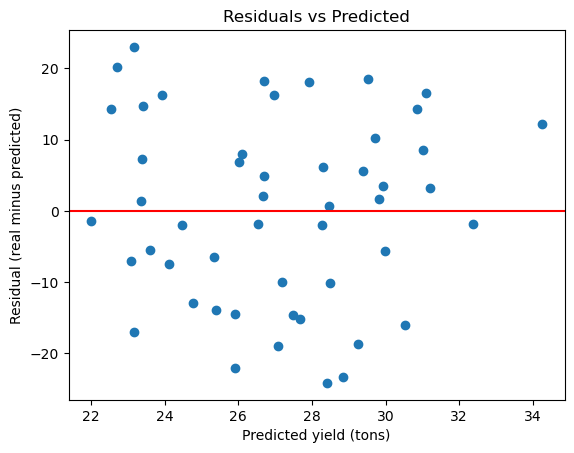

In [16]:
X_const = sm.add_constant(X)
ols_model = sm.OLS(y, X_const).fit()

fitted = ols_model.fittedvalues
residuals = ols_model.resid

plt.scatter(fitted, residuals)
plt.axhline(0, color='red')
plt.xlabel('Predicted yield (tons)')
plt.ylabel('Residual (real minus predicted)')
plt.title('Residuals vs Predicted')
plt.show()

## Overall Conclusion
Six methods (correlation, ANOVA, regression F-test, adjusted R-squared, train/test, cross-validation) agree: these variables show no reliable relationship with yield in this 50-farm dataset. This does not prove the inputs do not matter on real farms. It shows this dataset cannot demonstrate it, probably because of the small sample and missing variables such as rainfall and temperature.